# Overlapping Mitigation

### <i> Using TomeKLinks, SmoteTomek, ClusterCentroids

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("../diabetes.csv")
df

,pregnant,glucose,pressure,triceps,insulin,mass,pedigree,age,diabetes
0,1,89,66,23,94,28.1,0.167,21,neg
1,0,137,40,35,168,43.1,2.288,33,pos
2,3,78,50,32,88,31.0,0.248,26,pos
3,2,197,70,45,543,30.5,0.158,53,pos
4,1,189,60,23,846,30.1,0.398,59,pos
...,...,...,...,...,...,...,...,...,...
387,0,181,88,44,510,43.3,0.222,26,pos
388,1,128,88,39,110,36.5,1.057,37,pos
389,2,88,58,26,16,28.4,0.766,22,neg
390,10,101,76,48,180,32.9,0.171,63,neg


---

### The problem

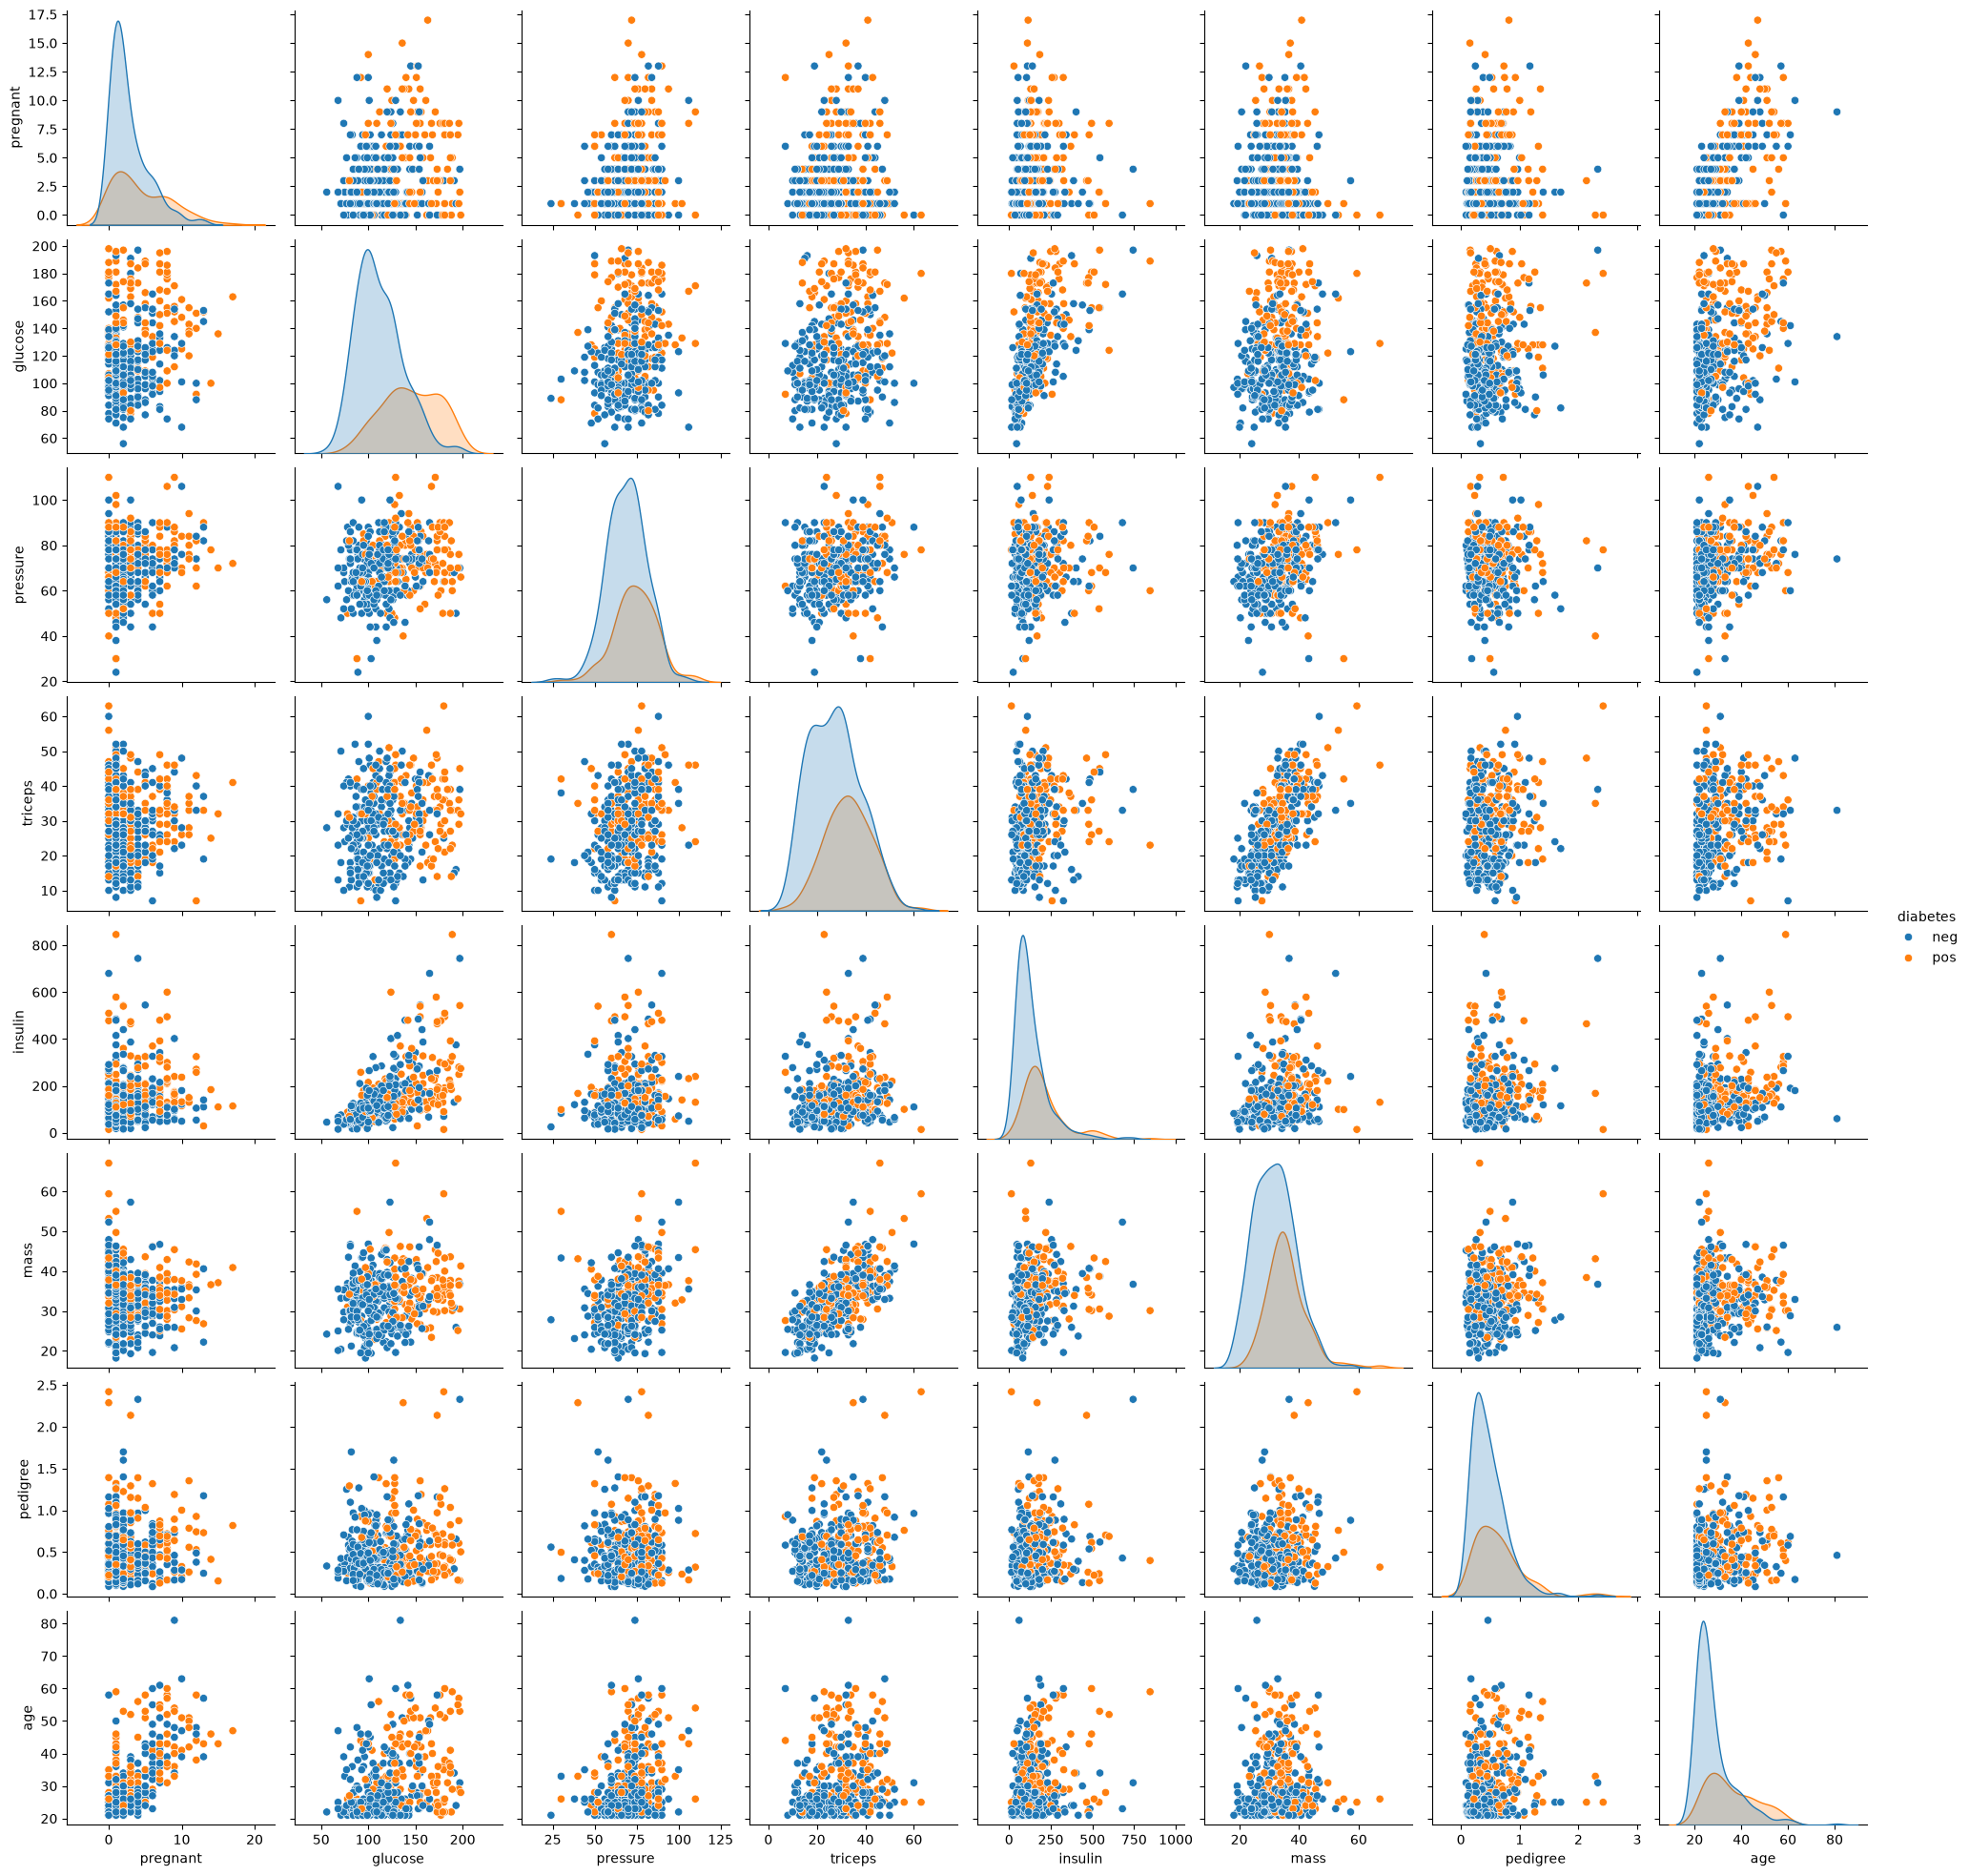

In [2]:
# The current problem is that our dataset has a significant amount of overlap that could 
# affect our ML models. Take a look.
sns.pairplot(df, hue="diabetes")

<Axes: xlabel='glucose', ylabel='mass'>

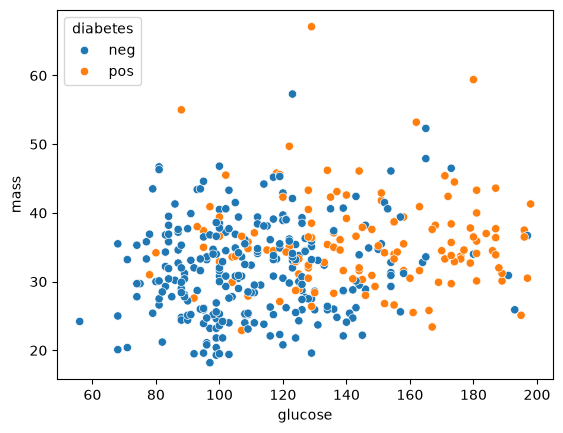

In [3]:
# Now let's take a particularly nasty overlap. Here.
sns.scatterplot(df, x="glucose", y="mass", hue="diabetes")

# In real life, does this overlap seem feasable? Probably.
# There's always some overlap (especially in health diagnosis data).

# But say this didn't reflect reality and there's some reason to 
# fix the overlap (to which there are many)...

---

### Encoding

In [4]:
# Binary encoding the `diabetes` column
variables = ['diabetes']

df[variables] = df[variables].replace({
    'neg': 0,
    'pos': 1
})

C:\Users\tuomas.valtanen\AppData\Local\Temp\ipykernel_19324\3524316922.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[variables] = df[variables].replace({


---

### TomeKLinks

In [5]:
from imblearn.under_sampling import TomekLinks

# X y split to prevent data leakage
X = df.drop(columns="diabetes", axis=1)
y = df["diabetes"]

# Let's use vanilla tomeklinks
tomek = TomekLinks()

# Fit and resample.
X_resampled, y_resampled = tomek.fit_resample(X, y)

# Make a new copy (so we don't have trouble with dependency)
df_resampled = X_resampled.copy()

# Add y back into the X rows
df_resampled["diabetes"] = y_resampled
df_resampled

,pregnant,glucose,pressure,triceps,insulin,mass,pedigree,age,diabetes
0,1,89,66,23,94,28.1,0.167,21,0
1,0,137,40,35,168,43.1,2.288,33,1
2,3,78,50,32,88,31.0,0.248,26,1
3,2,197,70,45,543,30.5,0.158,53,1
4,1,189,60,23,846,30.1,0.398,59,1
...,...,...,...,...,...,...,...,...,...
366,0,181,88,44,510,43.3,0.222,26,1
367,1,128,88,39,110,36.5,1.057,37,1
368,2,88,58,26,16,28.4,0.766,22,0
369,10,101,76,48,180,32.9,0.171,63,0


Text(0.5, 1.0, 'Original')

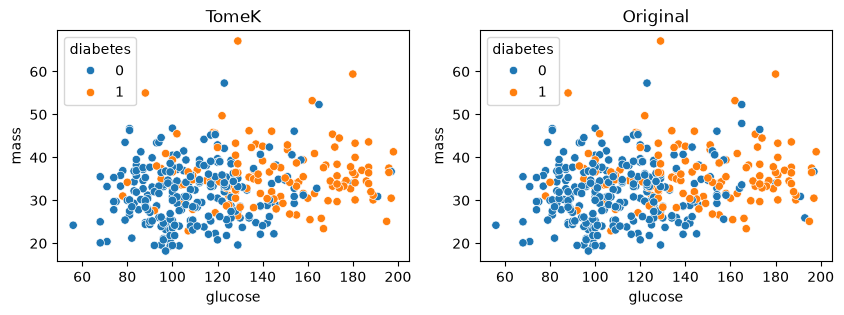

In [6]:
# Let's look at it again. How did it perform?
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
sns.scatterplot(df_resampled, x="glucose", y="mass", hue="diabetes", ax=axes[0])
sns.scatterplot(df, x="glucose", y="mass", hue="diabetes", ax=axes[1]) 

axes[0].set_title("TomeK")
axes[1].set_title("Original")

# Quite underwhelming... That sort of makes sense though. Tomek is notoriously 
# conservative, even with large amounts of data. Hence why it's commonly used with SMOTE first.

In [7]:
# But let's do a sanity check. How many rows did it get rid of?
print(df.shape)
print(df_resampled.shape)

# It only dropped about 20 rows.

(392, 9)
(371, 9)


---

### SmoteTomek

<i> Smote + TomeKLinks is a really popular way to solve overlap because it the strategy is simple and effective:

 Oversample the minority + clean the class boundary. 
 
 

In [8]:
from imblearn.combine import SMOTETomek

# X y split to prevent data leakage
X = df.drop(columns="diabetes", axis=1)
y = df["diabetes"]

# Initialize the SmoteTomek object
smote_tomek = SMOTETomek(
    random_state=321
)

# And fit it with the all of the features in the dataset. 
X_resampled, y_resampled = smote_tomek.fit_resample(X, y)

# Make a new copy (so we don't have trouble with dependency)
df_resampled = X_resampled.copy()

# Add y back into the X rows
df_resampled["diabetes"] = y_resampled
df_resampled

,pregnant,glucose,pressure,triceps,insulin,mass,pedigree,age,diabetes
0,1,89,66,23,94,28.100000,0.167000,21,0
1,0,137,40,35,168,43.100000,2.288000,33,1
2,3,78,50,32,88,31.000000,0.248000,26,1
3,2,197,70,45,543,30.500000,0.158000,53,1
4,1,189,60,23,846,30.100000,0.398000,59,1
...,...,...,...,...,...,...,...,...,...
499,5,137,78,35,363,44.420230,0.255631,44,1
500,1,194,67,39,620,30.397406,0.219557,54,1
501,3,169,65,37,223,34.854019,0.358818,29,1
502,0,121,89,50,220,49.381159,0.343476,31,1


Text(0.5, 1.0, 'Original')

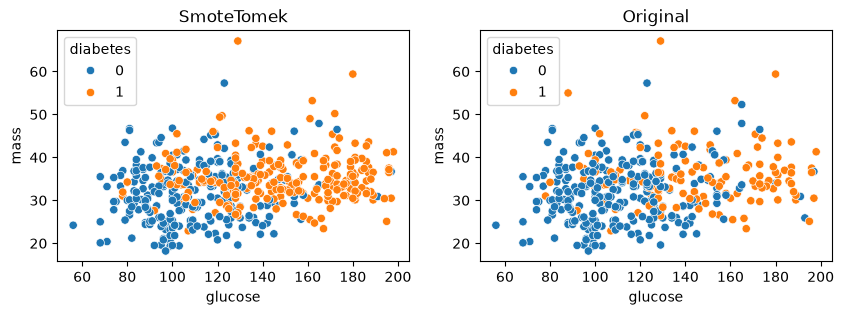

In [9]:
# Let's look at it again. How did it perform?
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

sns.scatterplot(df, x="glucose", y="mass", hue="diabetes", ax=axes[1])    
sns.scatterplot(df_resampled, x="glucose", y="mass", hue="diabetes", ax=axes[0])

axes[0].set_title("SmoteTomek")
axes[1].set_title("Original")


# Now, we're seeing significantly less problems with overlap (though it still exists!)

In [10]:
# But let's do a sanity check. How many rows did it get rid of?
print(df.shape)
print(df_resampled.shape)


(392, 9)
(504, 9)


--- 

### ClusterCentroids

In [11]:
from imblearn.under_sampling import ClusterCentroids

# X y split to prevent data leakage
X = df.drop(columns="diabetes", axis=1)
y = df["diabetes"]


cc = ClusterCentroids(
    sampling_strategy="auto",
    random_state=321
)

X_resampled, y_resampled = cc.fit_resample(X, y)

# Make a new copy (so we don't have trouble with dependency)
df_resampled = X_resampled.copy()

# Add y back into the X rows
df_resampled["diabetes"] = y_resampled
df_resampled

,pregnant,glucose,pressure,triceps,insulin,mass,pedigree,age,diabetes
0,3,123,100,35,240,57.300000,0.880000,22,0
1,2,101,58,35,90,21.800000,0.155000,22,0
2,5,155,84,44,545,38.700000,0.619000,34,0
3,2,103,56,21,161,32.166667,0.390333,22,0
4,9,124,70,33,402,35.400000,0.282000,34,0
...,...,...,...,...,...,...,...,...,...
255,2,174,88,37,120,44.500000,0.646000,24,1
256,11,120,80,37,150,42.300000,0.785000,48,1
257,3,187,70,22,200,36.400000,0.408000,36,1
258,0,181,88,44,510,43.300000,0.222000,26,1


<Axes: xlabel='glucose', ylabel='mass'>

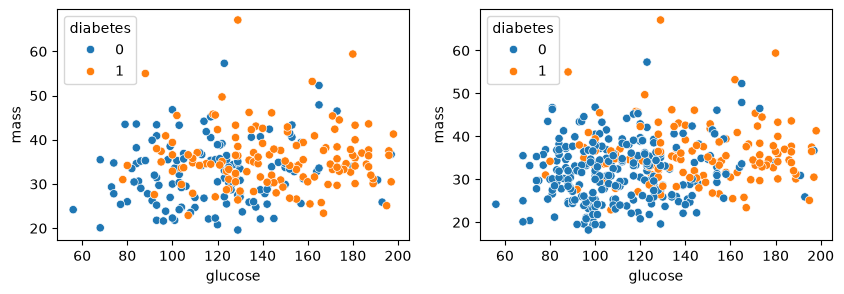

In [12]:
# Let's look at it again. How did it perform?
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
sns.scatterplot(df, x="glucose", y="mass", hue="diabetes", ax=axes[1])    
sns.scatterplot(df_resampled, x="glucose", y="mass", hue="diabetes", ax=axes[0])

# Not bad too, but still a little underwhelming.

In [13]:
# But let's do a sanity check. How many rows did it get rid of?
print(df.shape)
print(df_resampled.shape)

(392, 9)
(260, 9)
